In [93]:
# Setup
import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

DATA_FILE = "tep_sp_clean_noisy.h5"
CLEAN_FILE = "tep_sp_clean.h5"
OUT_FILE = DATA_FILE.replace(".h5", "_filter.h5")

FILTER = "moving_average"
# FILTER = "ewma"
WINDOW = 9                  # moving average length in samples
ALPHA = 0.2                 # EWMA weight of the newest sample

FILTERED_GROUPS = ["xmeas", "xmv", "sp"]
T_RANGE = (100, 130)

In [94]:
# Load data
def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


data, names = {}, {}
with h5py.File(DATA_FILE, "r") as f:
    t = f["t"][()] / 3600
    for key in FILTERED_GROUPS:
        data[key] = f[key][()]
        names[key] = read_names(f[key])
    sp = f["sp"][()]
    config = json.loads(f.attrs["config"])

clean = {}
if CLEAN_FILE is not None:
    with h5py.File(CLEAN_FILE, "r") as f:
        for key in FILTERED_GROUPS:
            clean[key] = f[key][()]

# Samples where a changed set point is off its nominal value
nominal = {int(k): v for k, v in config["setpoints"].items()}
changed = sorted({k for k, _, _ in config["setpoint_schedule"]})
off_nominal = np.zeros(len(t), dtype=bool)
for k in changed:
    off_nominal |= np.abs(sp[:, k - 1] - nominal[k]) > 1e-9

SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)
print(f"{DATA_FILE}: {len(t)} samples, {t[0]:.2f} - {t[-1]:.2f} h, every {SAMPLE_MIN:.0f} min, noise: {config['noise']}")

tep_sp_clean_noisy.h5: 5750 samples, 0.10 - 575.00 h, every 6 min, noise: True


In [95]:
# Filter
def moving_average(x, window):
    out = np.zeros_like(x)
    for i in range(len(x)):
        start = max(0, i - window + 1)
        out[i] = x[start:i + 1].mean(axis=0)
    return out


def ewma(x, alpha):
    out = np.zeros_like(x)
    out[0] = x[0]
    for i in range(1, len(x)):
        out[i] = alpha * x[i] + (1 - alpha) * out[i - 1]
    return out


def apply_filter(x):
    if FILTER == "moving_average":
        return moving_average(x, WINDOW)
    if FILTER == "ewma":
        return ewma(x, ALPHA)
    raise ValueError(f"unknown FILTER {FILTER}")


filtered = {}
for key in FILTERED_GROUPS:
    filtered[key] = apply_filter(data[key])

if FILTER == "moving_average":
    FILTER_LABEL = f"moving average, {WINDOW} samples"
    delay = (WINDOW - 1) / 2   # samples
else:
    FILTER_LABEL = f"EWMA, alpha {ALPHA}"
    delay = (1 - ALPHA) / ALPHA   # samples
print(f"{FILTER_LABEL}: average delay {delay:.1f} samples = {delay * SAMPLE_MIN:.0f} min")

moving average, 9 samples: average delay 4.0 samples = 24 min


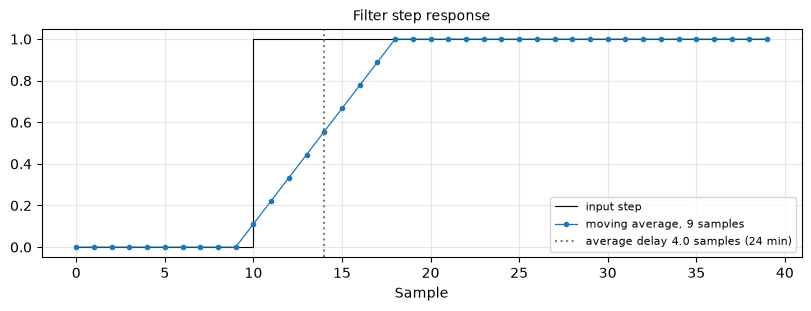

In [96]:
# Filter delay: response to a unit step
step = np.zeros((40, 1))
step[10:] = 1.0
step_filtered = apply_filter(step)

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.step(np.arange(40), step[:, 0], where="post", color="black", lw=0.8, label="input step")
ax.plot(np.arange(40), step_filtered[:, 0], "o-", color="tab:blue", ms=3, lw=0.9, label=FILTER_LABEL)
ax.axvline(10 + delay, color="gray", ls=":", label=f"average delay {delay:.1f} samples ({delay * SAMPLE_MIN:.0f} min)")
ax.set_xlabel("Sample")
ax.set_title("Filter step response", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

In [97]:
# Noise left after filtering
rows = []
if clean:
    for key in FILTERED_GROUPS:
        for i in range(data[key].shape[1]):
            scale = clean[key][:, i].std()
            if scale == 0:
                continue
            rows.append({
                "variable": f"{key}_{i + 1}",
                "description": names[key][i],
                "noisy": np.sqrt(np.mean((data[key][:, i] - clean[key][:, i]) ** 2)) / scale,
                "filtered": np.sqrt(np.mean((filtered[key][:, i] - clean[key][:, i]) ** 2)) / scale,
            })
    noise_table = pd.DataFrame(rows).set_index("variable")
    print(f"Mean scaled RMSE vs {CLEAN_FILE}: noisy {noise_table['noisy'].mean():.2f}, "
          f"filtered {noise_table['filtered'].mean():.2f} ({FILTER_LABEL})")
    pd.set_option("display.max_rows", 100)
    display(noise_table.round(3))

Mean scaled RMSE vs tep_sp_clean.h5: noisy 2.67, filtered 1.13 (moving average, 9 samples)


,description,noisy,filtered
variable,,,
xmeas_1,A feed (kscmh),0.829,0.651
xmeas_2,D feed (kg/h),1.709,0.626
xmeas_3,E feed (kg/h),0.601,0.401
xmeas_4,A and C feed (kscmh),0.705,0.542
xmeas_5,Recycle flow (kscmh),95.154,31.685
xmeas_6,Reactor feed rate (kscmh),1.506,0.571
xmeas_7,Reactor pressure (kPa),0.277,0.347
xmeas_8,Reactor level (%),1.201,0.717
xmeas_9,Reactor temperature (C),0.047,0.215


In [98]:
# Plotting
def time_mask():
    if T_RANGE is None:
        return np.ones(len(t), dtype=bool)
    return (t >= T_RANGE[0]) & (t <= T_RANGE[1])


def grid(key, title, ncols, idx=None):
    shown = time_mask()
    idx = list(range(data[key].shape[1])) if idx is None else idx   # columns to plot
    n = len(idx)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows + 1.0), sharex=True,
                             squeeze=False, layout="constrained")
    for i, ax in zip(idx, axes.ravel()[:n]):
        ax.fill_between(t[shown], 0, 1, where=off_nominal[shown], color="tab:red", alpha=0.1,
                        transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
        ax.plot(t[shown], data[key][shown, i], color="0.6", lw=0.5, label="noisy")
        if clean:
            ax.plot(t[shown], clean[key][shown, i], color="black", lw=0.7, ls="--", label="clean run")
        ax.plot(t[shown], filtered[key][shown, i], color="tab:blue", lw=0.9, label="filtered")
        ax.set_xlim(t[shown][0], t[shown][-1])
        ax.set_title(f"{i + 1}. {names[key][i]}", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=len(labels), fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("Time (h)", fontsize=8)
    fig.suptitle(f"{title} - {DATA_FILE}, {t[shown][0]:.1f} - {t[shown][-1]:.1f} h, {FILTER_LABEL}", fontsize=11)
    plt.show()

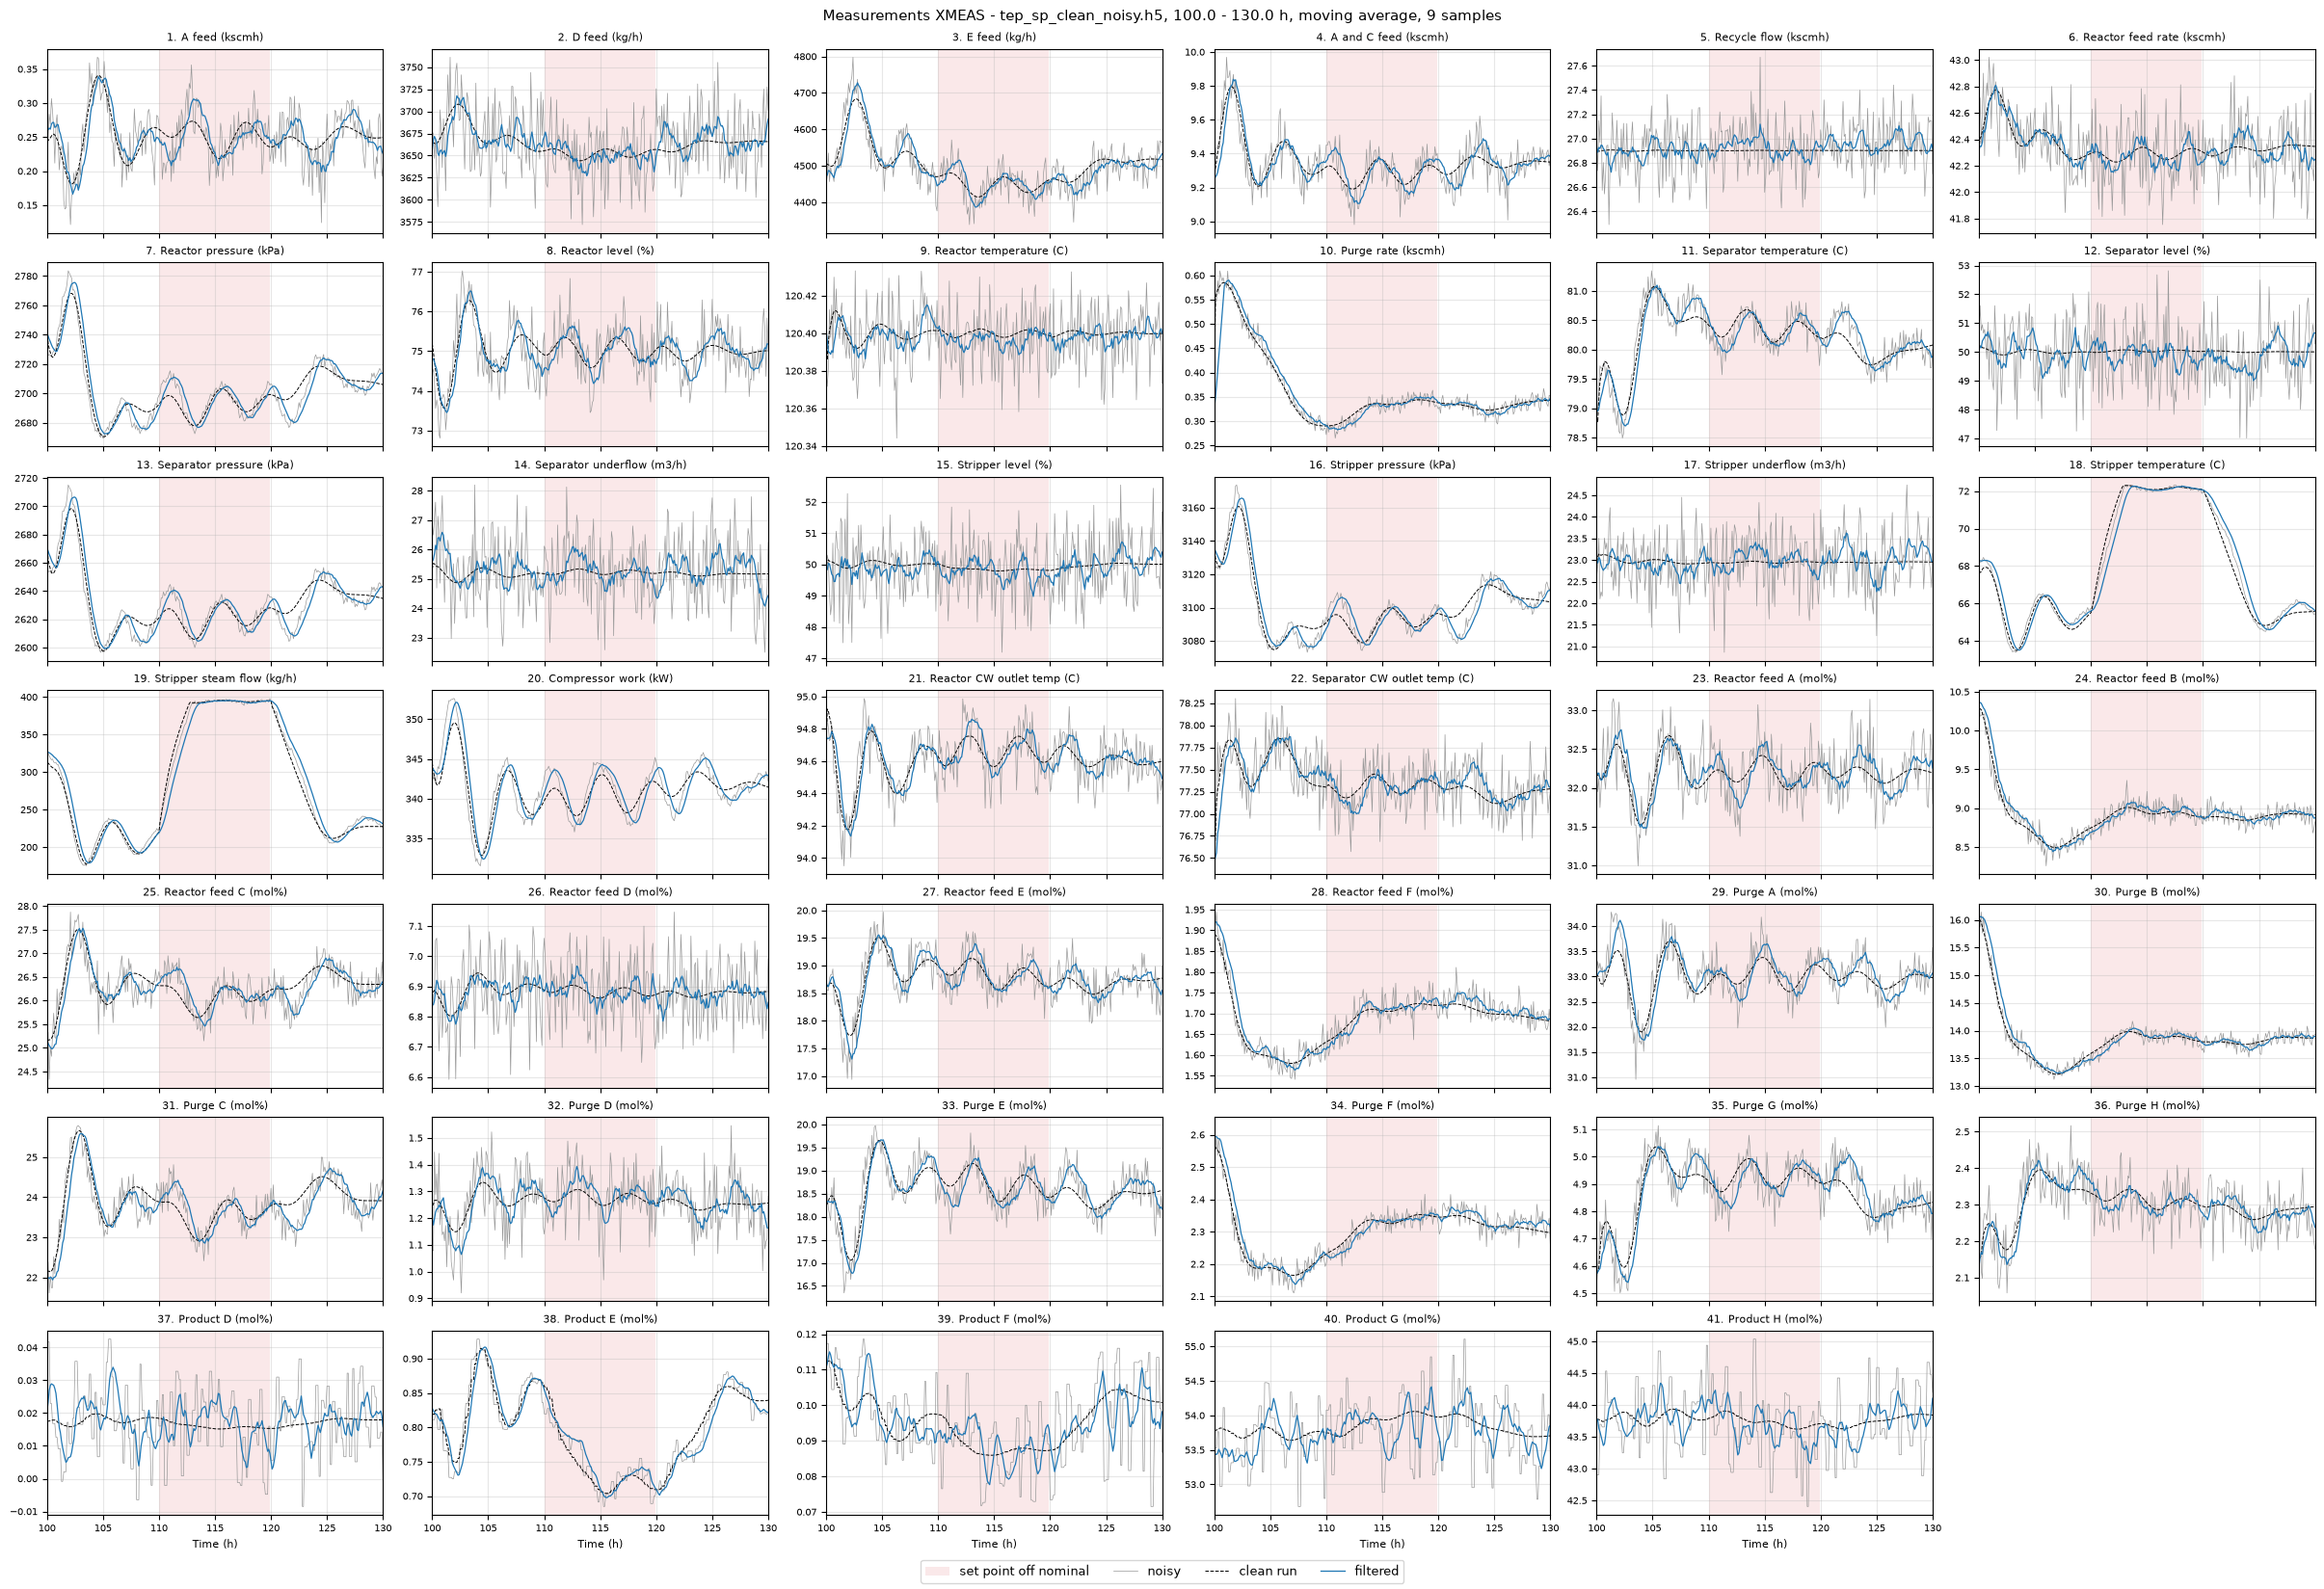

In [99]:
# Measurements XMEAS, before and after filtering
grid("xmeas", "Measurements XMEAS", 6)

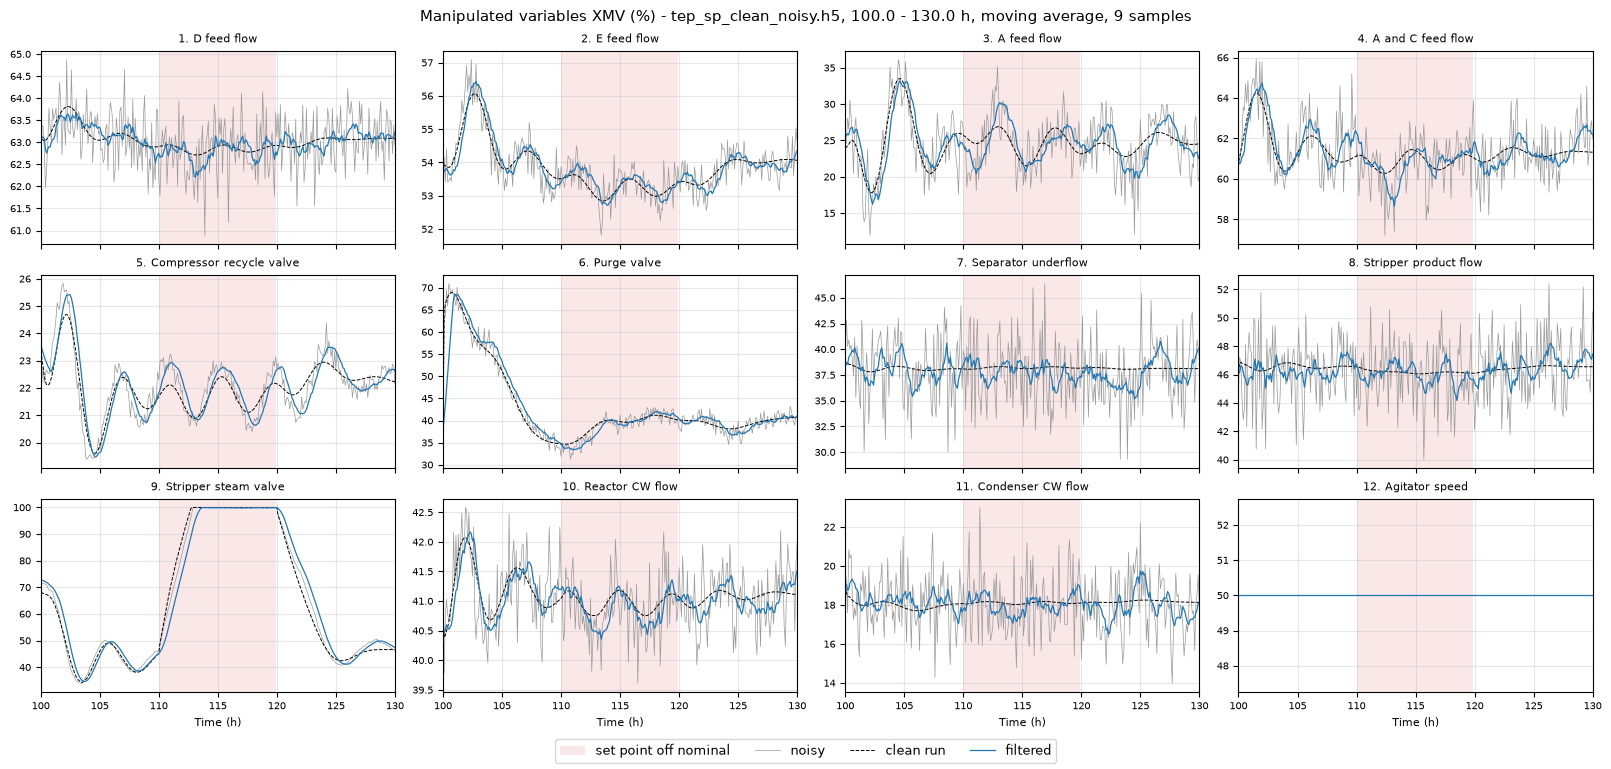

In [100]:
# Manipulated variables XMV, before and after filtering
grid("xmv", "Manipulated variables XMV (%)", 4)

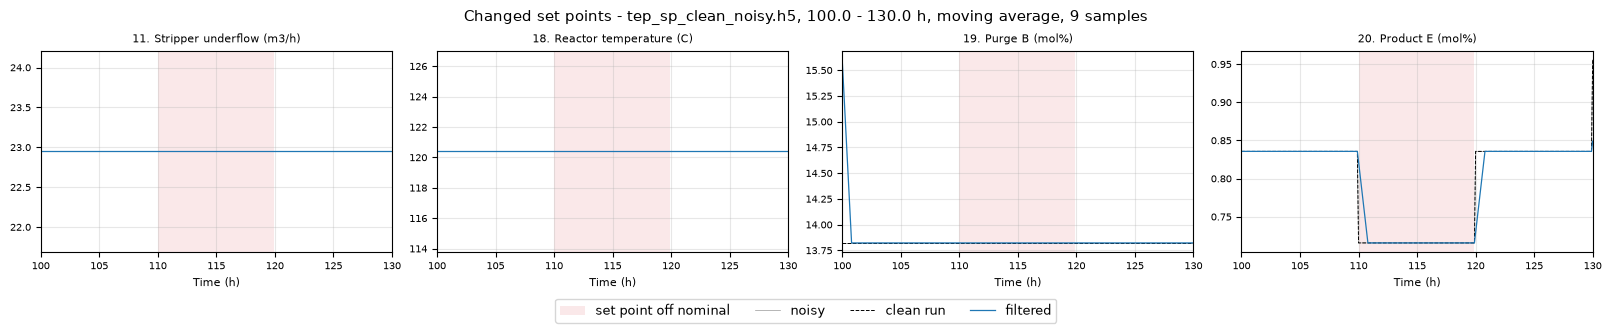

In [101]:
# Changed set points, before and after filtering
grid("sp", "Changed set points", 4, [k - 1 for k in changed])

In [102]:
# Save filtered data
with h5py.File(DATA_FILE, "r") as src, h5py.File(OUT_FILE, "w") as dst:
    for name, value in src.attrs.items():
        dst.attrs[name] = value
    for key in src.keys():
        if key in FILTERED_GROUPS:
            ds = dst.create_dataset(key, data=filtered[key])
        else:
            ds = dst.create_dataset(key, data=src[key][()])
        for name, value in src[key].attrs.items():
            ds.attrs[name] = value
    dst.attrs["filter"] = json.dumps({
        "source": DATA_FILE,
        "filter": FILTER,
        "window": WINDOW if FILTER == "moving_average" else None,
        "alpha": ALPHA if FILTER == "ewma" else None,
        "groups": FILTERED_GROUPS,
        "delay_samples": delay,
    })
print(f"Saved {FILTER_LABEL} filtered data to {OUT_FILE}")

Saved moving average, 9 samples filtered data to tep_sp_clean_noisy_filter.h5
